In [ ]:
Cell 1: Imports & Data Inspection

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, root_mean_squared_error, r2_score
)

# Load datasets
clf_df = pd.read_csv("classification_escalation.csv")
reg_df = pd.read_csv("resolution_time_regression.csv")

print("=== Classification Dataset ===")
print("Shape:", clf_df.shape)
display(clf_df.head())
print("Missing values:\n", clf_df.isnull().sum())
print("Target distribution:\n", clf_df["escalated"].value_counts(normalize=True))

print("\n=== Regression Dataset ===")
print("Shape:", reg_df.shape)
display(reg_df.head())
print("Missing values:\n", reg_df.isnull().sum())
print("Target summary:\n", reg_df["resolution_time_hours"].describe())

=== Classification Dataset ===
Shape: (900, 7)


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,T0000,2.0,15.0,Medium,Email,61.818896,0
1,T0001,9.0,6.0,Critical,Chat,110.024317,0
2,T0002,10.0,8.0,High,Phone,36.311244,0
3,T0003,2.0,1.0,Medium,Phone,85.127855,0
4,T0004,8.0,14.0,Medium,Chat,18.225059,0


Missing values:
 ticket_id                  0
complexity_score          22
team_experience_years     36
priority                  13
channel                    9
customer_tenure_months    31
escalated                  0
dtype: int64
Target distribution:
 escalated
0    0.787778
1    0.212222
Name: proportion, dtype: float64

=== Regression Dataset ===
Shape: (800, 7)


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
0,R0000,7.0,10.0,Medium,Chat,32.638377,8.38724
1,R0001,4.0,15.0,Medium,Chat,45.273760,0.50000
2,R0002,4.0,13.0,Low,Portal,44.878323,0.50000
3,R0003,1.0,10.0,High,Phone,40.095034,0.50000
4,R0004,3.0,15.0,Low,Portal,47.451134,0.50000


Missing values:
 ticket_id                  0
complexity_score          16
team_experience_years     24
priority                   0
channel                    0
customer_tenure_months    20
resolution_time_hours      0
dtype: int64
Target summary:
 count    800.000000
mean       5.873160
std        4.144974
min        0.500000
25%        2.631319
50%        5.387386
75%        8.345903
max       27.488229
Name: resolution_time_hours, dtype: float64


In [ ]:
Cell 2: Helper Function for Dynamic Column Preprocessing

In [14]:
def build_preprocessor(X_df):

    # Identify numeric columns
    numeric_cols = X_df.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    # Identify categorical columns (warning fixed)
    categorical_cols = X_df.select_dtypes(
        include=["str", "category", "bool"]
    ).columns.tolist()

    # Numeric preprocessing pipeline
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical preprocessing pipeline
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine both preprocessing pipelines
    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    return preprocessor

In [8]:
Cell 3 — Experiment A: Classification setup and 5-fold CV

In [15]:
# 1. Exclude ticket_id (if present) and separate target 'escalated'
drop_cols_clf = [c for c in ["ticket_id", "escalated"] if c in clf_df.columns]

X_clf = clf_df.drop(columns=drop_cols_clf)
y_clf = clf_df["escalated"]


# 2. Stratified 75/25 train/test split
# Hold out the test set until final evaluation

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=42, stratify=y_clf
)


# 3. Build preprocessing for classification

preprocessor_clf = build_preprocessor(X_train_clf)


# 4. Candidate classification models

clf_candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}


# 5. Identical 5-fold StratifiedKFold CV

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

clf_cv_rows = []

for name, estimator in clf_candidates.items():

    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor_clf),
        ("model", estimator)
    ])

    scores = cross_validate(
        pipe,
        X_train_clf,
        y_train_clf,
        cv=skf,
        scoring={
            "f1": "f1",
            "precision": "precision",
            "recall": "recall",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    clf_cv_rows.append({
        "Model": name,
        "Mean CV F1": scores["test_f1"].mean(),
        "Std CV F1": scores["test_f1"].std(),
        "Mean CV Precision": scores["test_precision"].mean(),
        "Mean CV Recall": scores["test_recall"].mean(),
        "Mean CV ROC-AUC": scores["test_roc_auc"].mean()
    })


# 6. Display results

clf_cv_df = pd.DataFrame(clf_cv_rows)

print("Experiment A — 5-Fold Stratified CV Results:")

display(clf_cv_df.round(4))

Experiment A — 5-Fold Stratified CV Results:


,Model,Mean CV F1,Std CV F1,Mean CV Precision,Mean CV Recall,Mean CV ROC-AUC
0,Logistic Regression,0.3822,0.0538,0.6237,0.2798,0.7941
1,k-NN (k=15),0.2146,0.1227,0.5380,0.1401,0.7442
2,Decision Tree,0.4014,0.1041,0.4023,0.4108,0.6190


In [ ]:
Cell 4: Experiment A — Hyperparameter Tuning & Single Test Evaluation
Here we tune Logistic Regression (testing C and class_weight to handle class imbalance and boost F1) alongside Decision Tree (max_depth, min_samples_leaf, class_weight) so you can compare tuned candidates via CV before evaluating the single best model on X_test_clf.

Tuned Logistic Regression | Best Params: {'model__C': 0.01, 'model__class_weight': 'balanced'} | Best CV F1: 0.5316
Tuned Decision Tree       | Best Params: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 20} | Best CV F1: 0.4975

=== Final Test Set Evaluation: Tuned Logistic Regression ===
              precision    recall  f1-score   support

           0     0.8933    0.7571    0.8196       177
           1     0.4267    0.6667    0.5203        48

    accuracy                         0.7378       225
   macro avg     0.6600    0.7119    0.6699       225
weighted avg     0.7938    0.7378    0.7557       225

Confusion Matrix Breakdown -> TN: 134, FP: 43, FN: 16, TP: 32


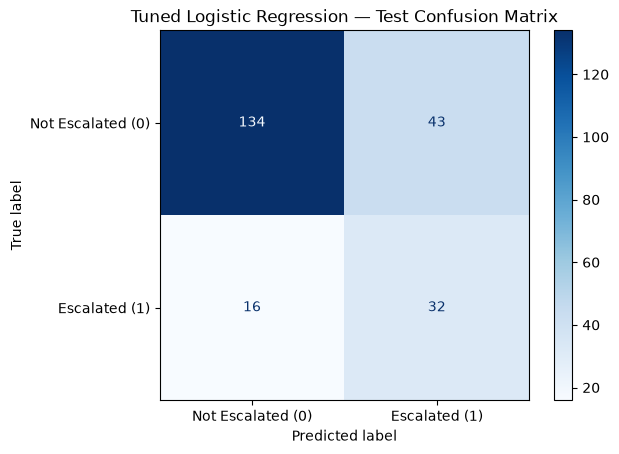

In [17]:
# Tune Logistic Regression
lr_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor_clf),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "model__class_weight": [None, "balanced"]
}

lr_grid = GridSearchCV(
    estimator=lr_pipe,
    param_grid=lr_param_grid,
    cv=skf,
    scoring="f1",
    n_jobs=-1
)
lr_grid.fit(X_train_clf, y_train_clf)

# Tune Decision Tree
dt_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor_clf),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_param_grid = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__class_weight": [None, "balanced"]
}

dt_grid = GridSearchCV(
    estimator=dt_pipe,
    param_grid=dt_param_grid,
    cv=skf,
    scoring="f1",
    n_jobs=-1
)
dt_grid.fit(X_train_clf, y_train_clf)

print(f"Tuned Logistic Regression | Best Params: {lr_grid.best_params_} | Best CV F1: {lr_grid.best_score_:.4f}")
print(f"Tuned Decision Tree       | Best Params: {dt_grid.best_params_} | Best CV F1: {dt_grid.best_score_:.4f}")

# Select winner based strictly on CV F1
best_clf_model = lr_grid.best_estimator_ if lr_grid.best_score_ >= dt_grid.best_score_ else dt_grid.best_estimator_
best_clf_name = "Tuned Logistic Regression" if lr_grid.best_score_ >= dt_grid.best_score_ else "Tuned Decision Tree"

# Evaluate ONCE on the held-out test set
y_pred_test_clf = best_clf_model.predict(X_test_clf)

print(f"\n=== Final Test Set Evaluation: {best_clf_name} ===")
print(classification_report(y_test_clf, y_pred_test_clf, digits=4))

cm = confusion_matrix(y_test_clf, y_pred_test_clf)
tn, fp, fn, tp = cm.ravel()
print(f"Confusion Matrix Breakdown -> TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Escalated (0)", "Escalated (1)"])
disp.plot(cmap="Blues")
plt.title(f"{best_clf_name} — Test Confusion Matrix")
plt.show()

In [ ]:
Cell 5: Experiment B — Regression Setup, Outlier Check & 5-Fold CV

In [19]:
# 1. Exclude ticket_id (if present) and separate target 'resolution_time_hours'
drop_cols_reg = [c for c in ["ticket_id", "resolution_time_hours"] if c in reg_df.columns]
X_reg = reg_df.drop(columns=drop_cols_reg)
y_reg = reg_df["resolution_time_hours"]

# Check target skewness / outliers
q1, median, q3 = np.percentile(y_reg, [25, 50, 75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outliers = y_reg[y_reg > upper_fence]
print(f"Target Median: {median:.2f}h | IQR: {iqr:.2f}h | Upper Fence: {upper_fence:.2f}h | Outlier Count: {len(outliers)} ({len(outliers)/len(y_reg):.1%})")

# 2. Train/test split (75/25)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=42
)

# 3. Candidate regression pipelines
preprocessor_reg = build_preprocessor(X_train_reg)

reg_candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression (alpha=1.0)": Ridge(alpha=1.0, random_state=42),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42)
}

# 4. Identical 5-fold KFold CV using MAE (and RMSE for comparison)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

reg_cv_rows = []
for name, estimator in reg_candidates.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor_reg),
        ("model", estimator)
    ])
    
    scores = cross_validate(
        pipe, X_train_reg, y_train_reg,
        cv=kf,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )
    
    # Negate scikit-learn's negative error scores back to positive hours
    mae_scores = -scores["test_mae"]
    rmse_scores = -scores["test_rmse"]
    
    reg_cv_rows.append({
        "Model": name,
        "Mean CV MAE": mae_scores.mean(),
        "Std CV MAE": mae_scores.std(),
        "Mean CV RMSE": rmse_scores.mean(),
        "Std CV RMSE": rmse_scores.std(),
        "Mean CV R2": scores["test_r2"].mean()
    })

reg_cv_df = pd.DataFrame(reg_cv_rows)
print("\nExperiment B — 5-Fold CV Results:")
display(reg_cv_df.round(4))

Target Median: 5.39h | IQR: 5.71h | Upper Fence: 16.92h | Outlier Count: 10 (1.2%)

Experiment B — 5-Fold CV Results:


,Model,Mean CV MAE,Std CV MAE,Mean CV RMSE,Std CV RMSE,Mean CV R2
0,Linear Regression,2.0343,0.0956,2.9893,0.4273,0.4590
1,Ridge Regression (alpha=1.0),2.0346,0.0946,2.9892,0.4270,0.4591
2,Decision Tree Regressor,3.1445,0.3407,4.6152,0.5621,-0.3417


In [ ]:
Cell 6: Experiment B — Tuning Ridge & Decision Tree + Single Test Evaluation

In [20]:
# Tune Ridge Regression alpha
ridge_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor_reg),
    ("model", Ridge(random_state=42))
])
ridge_grid = GridSearchCV(
    estimator=ridge_pipe,
    param_grid={"model__alpha": [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]},
    cv=kf,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)
ridge_grid.fit(X_train_reg, y_train_reg)

# Tune Decision Tree Regressor depth & leaf size
dtr_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor_reg),
    ("model", DecisionTreeRegressor(random_state=42))
])
dtr_grid = GridSearchCV(
    estimator=dtr_pipe,
    param_grid={
        "model__max_depth": [2, 3, 4, 5, 7, 10, None],
        "model__min_samples_leaf": [1, 5, 10, 20]
    },
    cv=kf,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)
dtr_grid.fit(X_train_reg, y_train_reg)

ridge_best_mae = -ridge_grid.best_score_
ridge_best_std = ridge_grid.cv_results_["std_test_score"][ridge_grid.best_index_]

dtr_best_mae = -dtr_grid.best_score_
dtr_best_std = dtr_grid.cv_results_["std_test_score"][dtr_grid.best_index_]

print(f"Tuned Ridge         | Best Params: {ridge_grid.best_params_} | Mean CV MAE: {ridge_best_mae:.4f} (+/- {ridge_best_std:.4f})")
print(f"Tuned Decision Tree | Best Params: {dtr_grid.best_params_} | Mean CV MAE: {dtr_best_mae:.4f} (+/- {dtr_best_std:.4f})")

# Select best model based strictly on lowest Mean CV MAE
if dtr_best_mae < ridge_best_mae:
    best_reg_model = dtr_grid.best_estimator_
    best_reg_name = "Tuned Decision Tree Regressor"
else:
    best_reg_model = ridge_grid.best_estimator_
    best_reg_name = "Tuned Ridge Regression"

# Evaluate ONCE on the held-out test set
y_pred_test_reg = best_reg_model.predict(X_test_reg)
test_mae = mean_absolute_error(y_test_reg, y_pred_test_reg)
test_rmse = root_mean_squared_error(y_test_reg, y_pred_test_reg)
test_r2 = r2_score(y_test_reg, y_pred_test_reg)

print(f"\n=== Final Test Set Evaluation: {best_reg_name} ===")
print(f"Test MAE : {test_mae:.4f} hours")
print(f"Test RMSE: {test_rmse:.4f} hours")
print(f"Test R2  : {test_r2:.4f}")

Tuned Ridge         | Best Params: {'model__alpha': 0.01} | Mean CV MAE: 2.0343 (+/- 0.0956)
Tuned Decision Tree | Best Params: {'model__max_depth': 4, 'model__min_samples_leaf': 5} | Mean CV MAE: 2.3952 (+/- 0.1949)

=== Final Test Set Evaluation: Tuned Ridge Regression ===
Test MAE : 2.1383 hours
Test RMSE: 3.2738 hours
Test R2  : 0.3989


In [ ]:
Cell 7: Markdown Template for Your Required Final Report

# Lab 4 Final Report: Leakage-Safe Classification & Regression Pipelines

## 1. Problem Framing
* **Experiment A (Classification):** Predict whether an incoming customer support ticket will be escalated (`escalated` = 1 vs. 0) using ticket attributes (e.g., complexity score, priority, channel, team experience, customer tenure), excluding non-predictive identifier `ticket_id`. Because escalated tickets are a minority class, **F1 score** is used as the primary metric to balance precision and recall.
* **Experiment B (Regression):** Predict continuous ticket resolution time in hours (`resolution_time_hours`), excluding `ticket_id`. **Mean Absolute Error (MAE)** is used as the primary metric so predictions are directly interpretable in hours without excessive distortion from extreme long-tail tickets.

## 2. Preprocessing & Data Leakage Prevention
* **Preprocessing Steps:**
  * *Numeric features:* `SimpleImputer(strategy="median")` handles missing values robustly without distortion from skewed values, followed by `StandardScaler()` so distance-based (`k-NN`) and regularized (`LogisticRegression`, `Ridge`) models treat all numeric features on a comparable scale.
  * *Categorical features:* `SimpleImputer(strategy="most_frequent")` fills missing categories, followed by `OneHotEncoder(handle_unknown="ignore")` to convert nominal categories into binary indicators safely even if rare categories appear only in validation/test splits.
* **Leakage Prevention:** All imputers, scalers, and encoders are encapsulated inside a `ColumnTransformer` within a scikit-learn `Pipeline`. During 5-fold cross-validation (`cross_validate` and `GridSearchCV`), transformers fit exclusively on the 4 training folds and transform the 1 validation fold, ensuring zero statistics from validation or test data leak into training.

## 3. Validation Strategy & Candidate Search Space
* **Experiment A:** Stratified 75/25 train/test split (`random_state=42`) followed by 5-fold `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` on the training split. Candidates: `LogisticRegression` (tuned over `C` $\in \{0.01, 0.1, 1, 10, 100\}$ and `class_weight` $\in \{\text{None}, \text{"balanced"}\}$), `KNeighborsClassifier` ($k=15$), and `DecisionTreeClassifier` (tuned over `max_depth`, `min_samples_leaf`, and `class_weight`).
* **Experiment B:** 75/25 train/test split (`random_state=42`) followed by 5-fold `KFold(n_splits=5, shuffle=True, random_state=42)`. Candidates: `LinearRegression`, `Ridge` (tuned over `alpha` $\in \{0.01, 0.1, 1, 10, 50, 100\}$), and `DecisionTreeRegressor` (tuned over `max_depth` and `min_samples_leaf`).

## 4. Results Summary & Error Interpretation
*(Paste your generated CV tables and final test metrics from Cells 3–6 here.)*

* **False Positives vs. False Negatives (Experiment A):**
  * **False Positives (FP):** Routine tickets mistakenly flagged for escalation. These consume senior support capacity unnecessarily and can cause alert fatigue.
  * **False Negatives (FN):** Complex/urgent tickets that actually require escalation but are missed by the model. These cause SLA breaches, prolonged resolution delays, and customer churn—typically carrying a higher business cost than false positives.
* **Outliers and MAE vs. RMSE (Experiment B):**
  * Support resolution times are typically right-skewed with extreme upper-tail outliers (e.g., complex multi-day bugs).
  * **MAE** weights all errors linearly ($\frac{1}{n}\sum |y_i - \hat{y}_i|$), optimizing toward the conditional **median** and remaining robust to occasional extreme tickets.
  * **RMSE** squares errors before averaging ($\sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$), heavily penalizing large residuals on outlier tickets and optimizing toward the conditional **mean**. Consequently, RMSE may favor regularized linear models or deeper splits that chase extreme values, whereas MAE favors models that predict typical resolution times accurately.

## 5. Final Model Justification & Limitations
* **Justification:** Choose the pipeline with the strongest cross-validated primary metric (`F1` in Exp. A; `MAE` in Exp. B) and low fold-to-fold variance, verified once on the held-out test set.
* **Limitations:** Univariate median/mode imputation ignores feature correlations; modest sample sizes limit complex interaction discovery; and probability thresholds (default 0.50) may still require business-cost calibration.

---

## 6. Reflection Questions
1. **Why stratify the classification split?**
   Stratification preserves the exact class proportion of `escalated` tickets across both the training and test sets (and across every CV fold). Without stratification, random splits on imbalanced data can produce folds with unusually few positive cases, leading to noisy F1 estimates and poorly calibrated decision boundaries.
2. **Why must preprocessing be inside the pipeline?**
   If imputation, scaling, or encoding is fitted on the full dataset before splitting or before cross-validation, information from the validation/test folds (such as global medians, means, variances, or category levels) leaks into the training process. Placing preprocessing inside the `Pipeline` guarantees transformations are learned solely from training folds during each split.
3. **What does fold variability tell you?**
   The standard deviation of scores across the 5 CV folds measures **model stability and variance**. High fold variability indicates sensitivity to specific training subsets (overfitting or small-sample instability), meaning real-world performance on new data may fluctuate noticeably from the mean CV score.
4. **Why should the test set be evaluated only once?**
   The test set serves as an unbiased proxy for unseen production data. If you repeatedly evaluate models, tune hyperparameters, or adjust thresholds based on test-set performance, you indirectly overfit to the test set's specific noise, producing overly optimistic generalization estimates.
5. **What deployment constraints might change your choice?**
   * **Latency & Memory:** `k-NN` stores the entire training dataset and computes distances at inference time, making it slow for high-throughput ticket routing compared to `LogisticRegression` or `Ridge` (which require only a fast dot product).
   * **Interpretability & Auditability:** Support leads often need clear explanations for why a ticket was escalated or why an SLA estimate was given, favoring transparent linear/logistic coefficients or shallow decision trees.
   * **Capacity & Asymmetric Costs:** If senior engineers have strict escalation caps, a model with calibrated probabilities (`LogisticRegression`) allows dynamic threshold tuning to match staffing capacity.